# Quantifying Used-Car Depreciation Beyond Static Specifications: A Rate-Engineered Machine Learning Approach
## Final Report Notebook

- **Course**: CSE437 - Data Science
- **Dataset**: [Used Car Dataset (Kaggle)](https://www.kaggle.com/datasets/rishabhkarn/used-car-dataset) (Rishabh Karn)
- **Target Variable**: price_cleaned (Resale Price in Lakhs INR)
- **Notebook File**: Quantifying_Used_Car_Depreciation_Notebook.ipynb
- **Research Paper**: Quantifying_Used_Car_Depreciation_Paper.pdf


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats as sp_stats
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import RobustScaler, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, VotingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

import xgboost as xgb
import lightgbm as lgb

# Style settings
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 110


## 1. Data Collection & Loading
Loading the dataset from the project repository or Google Drive link.


In [2]:
# Load the dataset using the copied link
file_link = 'https://drive.google.com/file/d/1Dppzwwq0wKOUjO3rBUvthe8BPI0uJlbG/view?usp=sharing'

# Extract file ID from the copied share link and load directly
if 'drive.google.com' in file_link and '/d/' in file_link:
    file_id = file_link.split('/d/')[1].split('/')[0]
    download_url = f'https://drive.google.com/uc?id={file_id}'
else:
    download_url = file_link

try:
    df_raw = pd.read_csv(download_url)
except Exception:
    df_raw = pd.read_csv('used_cars.csv')

print("Dataset Shape:", df_raw.shape)
df_raw.head()


Dataset Shape: (1553, 15)


,Unnamed: 0,car_name,registration_year,insurance_validity,fuel_type,seats,kms_driven,ownsership,transmission,manufacturing_year,mileage(kmpl),engine(cc),max_power(bhp),torque(Nm),price(in lakhs)
0,0,2017 Mercedes-Benz S-Class S400,Jul-17,Comprehensive,Petrol,5,56000,First Owner,Automatic,2017,7.81,2996.0,2996.0,333.0,63.75
1,1,2020 Nissan Magnite Turbo CVT XV Premium Opt BSVI,Jan-21,Comprehensive,Petrol,5,30615,First Owner,Automatic,2020,17.40,999.0,999.0,9863.0,8.99
2,2,2018 BMW X1 sDrive 20d xLine,Sep-18,Comprehensive,Diesel,5,24000,First Owner,Automatic,2018,20.68,1995.0,1995.0,188.0,23.75
3,3,2019 Kia Seltos GTX Plus,Dec-19,Comprehensive,Petrol,5,18378,First Owner,Manual,2019,16.50,1353.0,1353.0,13808.0,13.56
4,4,2019 Skoda Superb LK 1.8 TSI AT,Aug-19,Comprehensive,Petrol,5,44900,First Owner,Automatic,2019,14.67,1798.0,1798.0,17746.0,24.00


## 2. Data Cleaning & Preprocessing
Cleaning steps:
1. Drop index column and remove duplicate records.
2. Filter out corrupted rows from web scraping errors.
3. Standardize column names and category labels (`ownership`, `insurance_validity`).
4. Parse numeric years from `manufacturing_year` and `registration_year`.
5. Fix web-scraping shifted columns and extract true horsepower (`real_max_power_bhp`) and engine displacement (`engine(cc)`).
6. Fix unscaled price values (convert INR values to Lakhs).
7. Impute missing values with column medians.


In [3]:
# Create copy for cleaning
df = df_raw.copy()

# 1. Drop index column & remove duplicates
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)
df.drop_duplicates(inplace=True)

# 2. Filter shifted scraping rows
valid_fuel = ['Petrol', 'Diesel', 'CNG']
valid_trans = ['Manual', 'Automatic']
valid_mask = (
    df['fuel_type'].isin(valid_fuel) &
    df['transmission'].isin(valid_trans) &
    df['ownsership'].str.startswith(('First', 'Second', 'Third', 'Fourth', 'Fifth', 'Test'), na=False)
)
df = df[valid_mask].copy()

# 3. Rename and standardize categories
df.rename(columns={'ownsership': 'ownership'}, inplace=True)
df['insurance_validity'] = df['insurance_validity'].replace({
    'Third Party insurance': 'Third Party',
    'Not Available': 'Third Party'
})

# 4. Parse manufacturing and registration year
df['manufacturing_year'] = pd.to_numeric(df['manufacturing_year'], errors='coerce')

def parse_reg_year(reg_val, mfg_val):
    if pd.isna(reg_val):
        return mfg_val
    reg_str = str(reg_val).strip()
    parts = reg_str.split('-')
    if len(parts) == 2:
        try:
            yr = int(parts[1])
            return 2000 + yr if yr < 100 else yr
        except:
            pass
    try:
        yr = int(float(reg_str))
        return yr
    except:
        return mfg_val

df['reg_year_clean'] = [parse_reg_year(r, m) for r, m in zip(df['registration_year'], df['manufacturing_year'])]

# 5. Fix web-scraping shifted columns and extract horsepower
# In shifted rows, mileage(kmpl) contains engine cc (> 50 kmpl),
# while torque(Nm) contains torque and engine(cc) contains power.
is_shifted = df['mileage(kmpl)'] > 50

df.loc[is_shifted, 'temp_eng'] = df.loc[is_shifted, 'mileage(kmpl)']
df.loc[~is_shifted, 'temp_eng'] = df.loc[~is_shifted, 'engine(cc)']
df['engine(cc)'] = pd.to_numeric(df['temp_eng'], errors='coerce')
df.drop(columns=['temp_eng'], inplace=True)
df.loc[is_shifted, 'mileage(kmpl)'] = np.nan

def clean_power(val):
    if pd.isna(val):
        return np.nan
    try:
        val = float(val)
        if val > 100000:
            s = str(int(val))
            return float(s[:3] + '.' + s[3:5])
        elif val > 1000:
            return val / 100.0
        elif val > 0:
            return val
    except:
        pass
    return np.nan

df['real_max_power_bhp'] = np.nan
df.loc[~is_shifted, 'real_max_power_bhp'] = df.loc[~is_shifted, 'torque(Nm)'].apply(clean_power)
df.loc[is_shifted, 'real_max_power_bhp'] = df.loc[is_shifted, 'engine(cc)'].apply(clean_power)

# 6. Correct price scale (convert raw INR entries to lakhs)
df['price_cleaned'] = df['price(in lakhs)'].apply(lambda x: x / 100000.0 if x > 1000 else x)

# Filter corrupted impossible values before imputation
df.loc[(df['engine(cc)'] < 600) | (df['engine(cc)'] > 5000), 'engine(cc)'] = np.nan
df.loc[(df['real_max_power_bhp'] < 30) | (df['real_max_power_bhp'] > 600), 'real_max_power_bhp'] = np.nan
df.loc[(df['mileage(kmpl)'] < 5) | (df['mileage(kmpl)'] > 40), 'mileage(kmpl)'] = np.nan

# 7. Impute missing values with medians
for col in ['mileage(kmpl)', 'engine(cc)', 'real_max_power_bhp', 'max_power(bhp)', 'torque(Nm)']:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

print("Cleaned Dataset Shape:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())


Cleaned Dataset Shape: (1108, 17)
Missing values remaining: 0


## 3. Feature Engineering
Creating engineered features based on our research question:
- `vehicle_age`: Age of the car relative to 2024.
- `usage_intensity`: Kilometers driven per year of ownership (`kms_driven / vehicle_age`).
- `power_density`: Specific engine output (`real_max_power_bhp / engine(cc)`).
- `registration_delay`: Gap between manufacturing year and registration year.
- `brand_segment`: Brand categorization (`Luxury` vs `Mainstream`).
- Log-transformed variables (`log_price`, `log_kms_driven`, `log_usage_intensity`).


In [4]:
# Feature Engineering
ref_year = 2024

# 1. Vehicle Age
df['vehicle_age'] = (ref_year - df['manufacturing_year']).clip(lower=1)

# 2. Registration Delay
df['registration_delay'] = (df['reg_year_clean'] - df['manufacturing_year']).clip(lower=0, upper=5)

# 3. Annual Usage Intensity
df['usage_intensity'] = df['kms_driven'] / df['vehicle_age']

# 4. Power Density Ratio
df['power_density'] = (df['real_max_power_bhp'] / df['engine(cc)']).clip(lower=0.03, upper=0.25)
df['power_density'] = df['power_density'].fillna(df['power_density'].median())

# 5. Brand Segment Extraction
df['brand'] = df['car_name'].apply(lambda x: str(x).split()[1] if len(str(x).split()) > 1 else 'Other')
df['brand'] = df['brand'].replace({'Maruti': 'Maruti Suzuki', 'Land': 'Land Rover'})

luxury_brands = ['Mercedes-Benz', 'BMW', 'Audi', 'Jaguar', 'Land Rover', 'Porsche', 'Volvo', 'Lexus', 'Mini', 'Jeep']
df['brand_segment'] = df['brand'].apply(lambda x: 'Luxury' if x in luxury_brands else 'Mainstream')

# 6. Log Transformations
df['log_price'] = np.log1p(df['price_cleaned'])
df['log_kms_driven'] = np.log1p(df['kms_driven'])
df['log_usage_intensity'] = np.log1p(df['usage_intensity'])

df[['vehicle_age', 'registration_delay', 'usage_intensity', 'power_density', 'brand_segment', 'price_cleaned']].head()


,vehicle_age,registration_delay,usage_intensity,power_density,brand_segment,price_cleaned
0,7,0,8000.00,0.111148,Luxury,63.75
1,4,1,7653.75,0.098729,Mainstream,8.99
2,6,0,4000.00,0.094236,Luxury,23.75
3,5,0,3675.60,0.102055,Mainstream,13.56
4,5,0,8980.00,0.098699,Mainstream,24.00


## 4. Exploratory Data Analysis (EDA)

### 4.1 Summary Statistics
Summary statistics for raw and engineered numerical features.


In [5]:
# Summary statistics table
num_cols = [
    'price_cleaned', 'kms_driven', 'manufacturing_year', 'vehicle_age',
    'usage_intensity', 'real_max_power_bhp', 'engine(cc)', 'mileage(kmpl)',
    'power_density', 'registration_delay'
]

summary_stats_df = pd.DataFrame(index=num_cols)
summary_stats_df['Mean'] = df[num_cols].mean().round(2)
summary_stats_df['Median'] = df[num_cols].median().round(2)
summary_stats_df['Std Dev'] = df[num_cols].std().round(2)
summary_stats_df['IQR'] = (df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25)).round(2)
summary_stats_df['Min'] = df[num_cols].min().round(2)
summary_stats_df['Max'] = df[num_cols].max().round(2)
summary_stats_df['Skewness'] = df[num_cols].skew().round(2)
summary_stats_df


,Mean,Median,Std Dev,IQR,Min,Max,Skewness
price_cleaned,13.74,6.74,17.19,9.46,0.70,99.00,2.45
kms_driven,53276.24,49067.00,43310.12,40000.00,620.00,810000.00,9.51
manufacturing_year,2017.32,2018.00,3.03,4.00,2007.00,2023.00,-0.41
vehicle_age,6.68,6.00,3.03,4.00,1.00,17.00,0.41
usage_intensity,8545.41,7600.00,9168.15,4900.21,163.64,202500.00,16.59
real_max_power_bhp,125.03,108.56,60.78,19.45,36.29,576.63,2.97
engine(cc),1566.07,1395.00,570.04,753.00,624.00,4663.00,1.62
mileage(kmpl),18.30,18.52,3.52,3.87,7.81,28.40,-0.12
power_density,0.08,0.07,0.02,0.02,0.03,0.25,1.88
registration_delay,0.07,0.00,0.29,0.00,0.00,2.00,4.13


*Observation: Resale price is right-skewed with a mean of 13.74 Lakhs and a median of 6.74 Lakhs due to high-end luxury models. Usage intensity shows an average annual run of ~8,500-9,800 km/year.*


### 4.2 Target Variable Distribution & Log-Transformation
Checking raw price vs log-transformed price distribution.


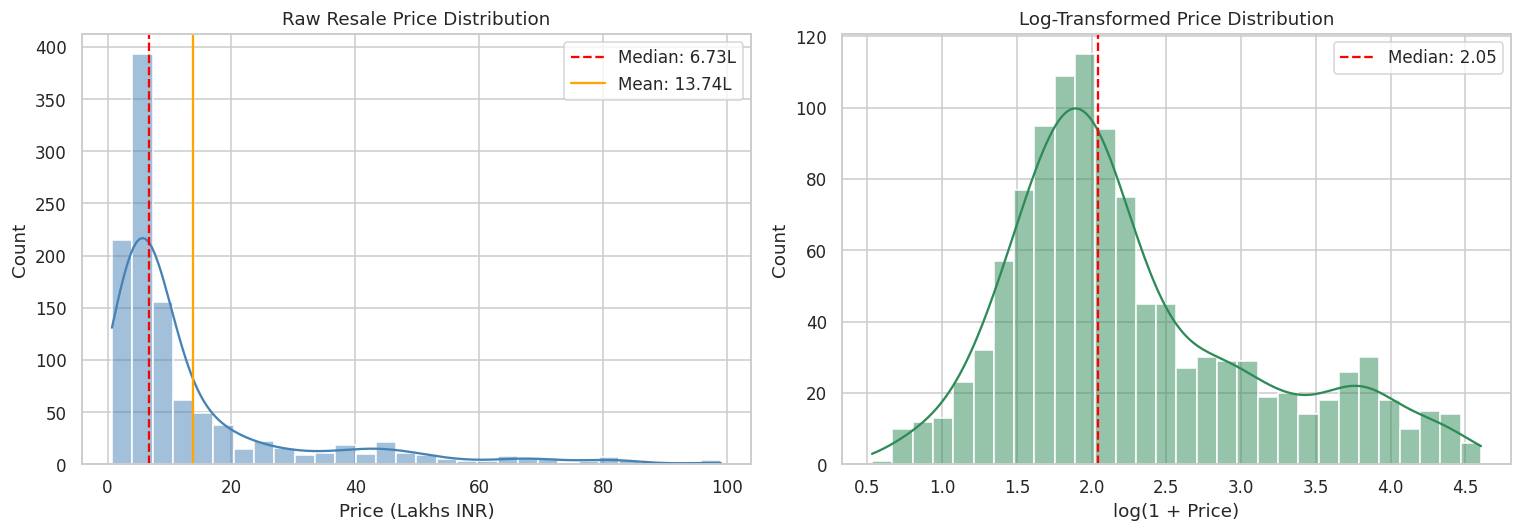

In [6]:
# Target distribution plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Price
sns.histplot(df['price_cleaned'], kde=True, ax=axes[0], color='steelblue', bins=30)
axes[0].axvline(df['price_cleaned'].median(), color='red', linestyle='--', label=f'Median: {df["price_cleaned"].median():.2f}L')
axes[0].axvline(df['price_cleaned'].mean(), color='orange', linestyle='-', label=f'Mean: {df["price_cleaned"].mean():.2f}L')
axes[0].set_title('Raw Resale Price Distribution')
axes[0].set_xlabel('Price (Lakhs INR)')
axes[0].legend()

# Log Price
sns.histplot(df['log_price'], kde=True, ax=axes[1], color='seagreen', bins=30)
axes[1].axvline(df['log_price'].median(), color='red', linestyle='--', label=f'Median: {df["log_price"].median():.2f}')
axes[1].set_title('Log-Transformed Price Distribution')
axes[1].set_xlabel('log(1 + Price)')
axes[1].legend()

plt.tight_layout()
plt.show()


*Observation: The raw price has high positive skewness (+2.45), while the log transformation makes the distribution symmetric and bell-shaped (skewness +0.38).*


### 4.3 Outlier Detection
Checking outliers across numerical features using the 1.5 * IQR rule.


In [7]:
# Outlier analysis using IQR
outlier_cols = ['price_cleaned', 'kms_driven', 'usage_intensity', 'real_max_power_bhp']
outlier_list = []

for col in outlier_cols:
    q25 = df[col].quantile(0.25)
    q75 = df[col].quantile(0.75)
    iqr = q75 - q25
    upper_limit = q75 + 1.5 * iqr
    lower_limit = q25 - 1.5 * iqr
    outlier_count = ((df[col] < lower_limit) | (df[col] > upper_limit)).sum()
    outlier_list.append({
        'Feature': col,
        'Q1': round(q25, 2),
        'Q3': round(q75, 2),
        'IQR': round(iqr, 2),
        'Upper Limit': round(upper_limit, 2),
        'Outliers Count': outlier_count,
        'Outlier %': round(outlier_count / len(df) * 100, 2)
    })

pd.DataFrame(outlier_list).set_index('Feature')


,Q1,Q3,IQR,Upper Limit,Outliers Count,Outlier %
Feature,,,,,,
price_cleaned,4.50,13.96,9.46,28.15,151,13.63
kms_driven,30000.00,70000.00,40000.00,130000.00,14,1.26
usage_intensity,5305.34,10205.56,4900.21,17555.88,38,3.43
real_max_power_bhp,98.96,118.41,19.45,147.58,265,23.92


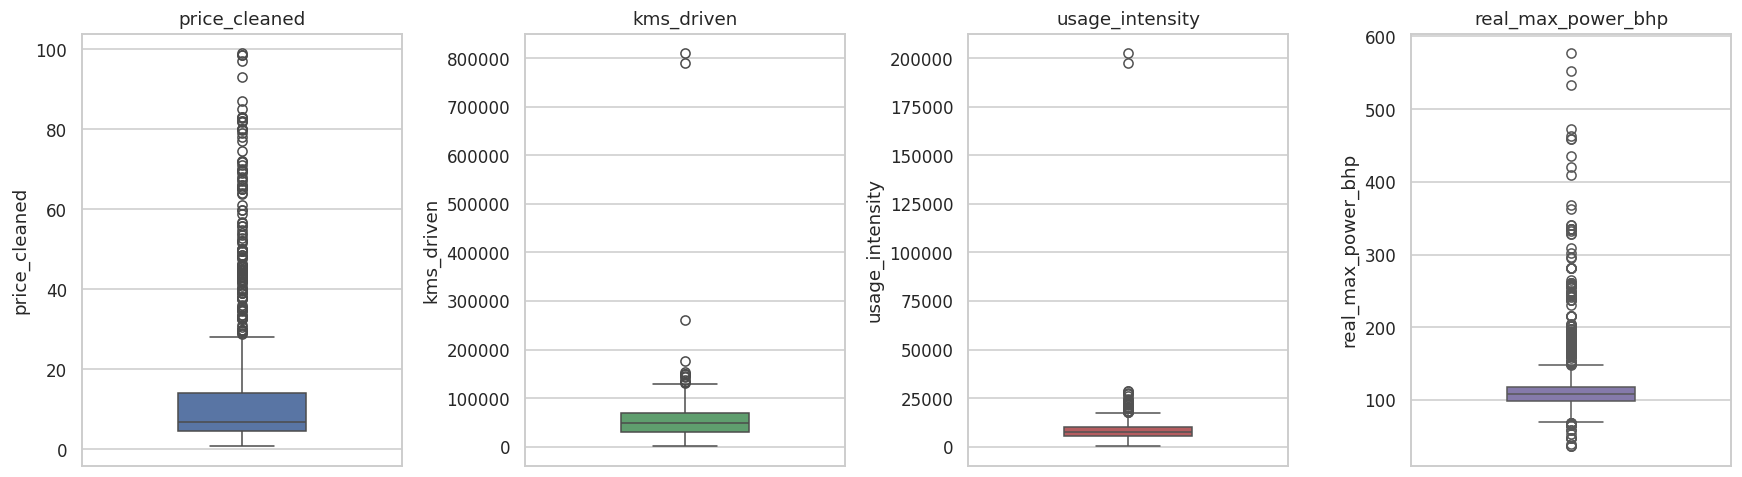

In [8]:
# Boxplots for numerical features
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
colors = ['#4c72b0', '#55a868', '#c44e52', '#8172b2']

for i, col in enumerate(outlier_cols):
    sns.boxplot(y=df[col], ax=axes[i], color=colors[i], width=0.4)
    axes[i].set_title(col)

plt.tight_layout()
plt.show()


*Observation: Price outliers represent high-value luxury cars (Mercedes, BMW, Porsche), while odometer outliers are genuine high-mileage commercial cars. Robust scaling and tree models are suitable to handle these.*


### 4.4 Correlation Analysis: Raw vs Engineered Features
Comparing correlation coefficients against vehicle price.


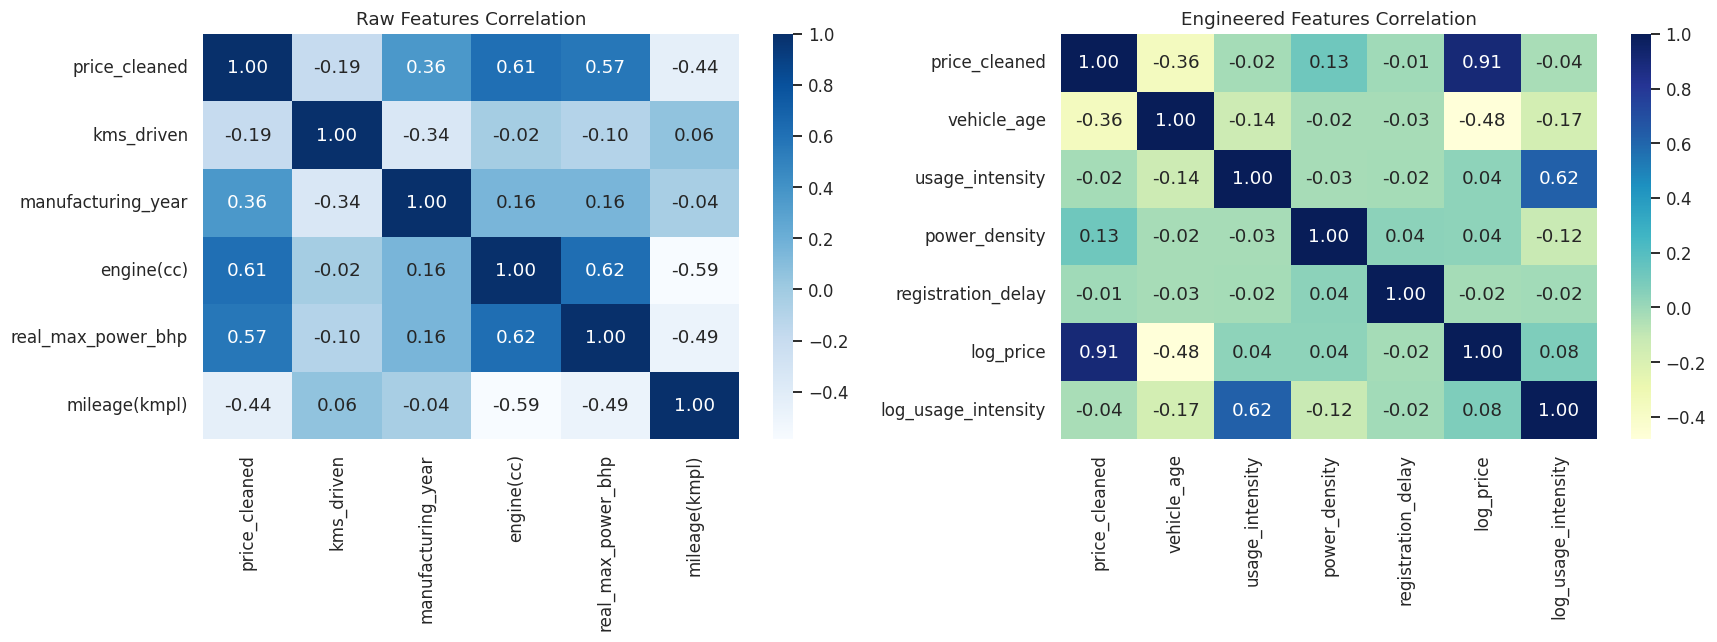

In [9]:
# Correlation heatmaps
raw_cols = ['price_cleaned', 'kms_driven', 'manufacturing_year', 'engine(cc)', 'real_max_power_bhp', 'mileage(kmpl)']
eng_cols = ['price_cleaned', 'vehicle_age', 'usage_intensity', 'power_density', 'registration_delay', 'log_price', 'log_usage_intensity']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(df[raw_cols].corr(), annot=True, fmt='.2f', cmap='Blues', ax=ax1)
ax1.set_title('Raw Features Correlation')

sns.heatmap(df[eng_cols].corr(), annot=True, fmt='.2f', cmap='YlGnBu', ax=ax2)
ax2.set_title('Engineered Features Correlation')

plt.tight_layout()
plt.show()


*Observation: Vehicle age has a stronger negative correlation with price (-0.36) than raw manufacturing year (+0.36). Power density and real horsepower exhibit positive correlations with resale price without introducing severe collinearity.*


### 4.5 Relationships & Group Comparisons
Visualizing price relationships with age, usage intensity, power density, and ownership.


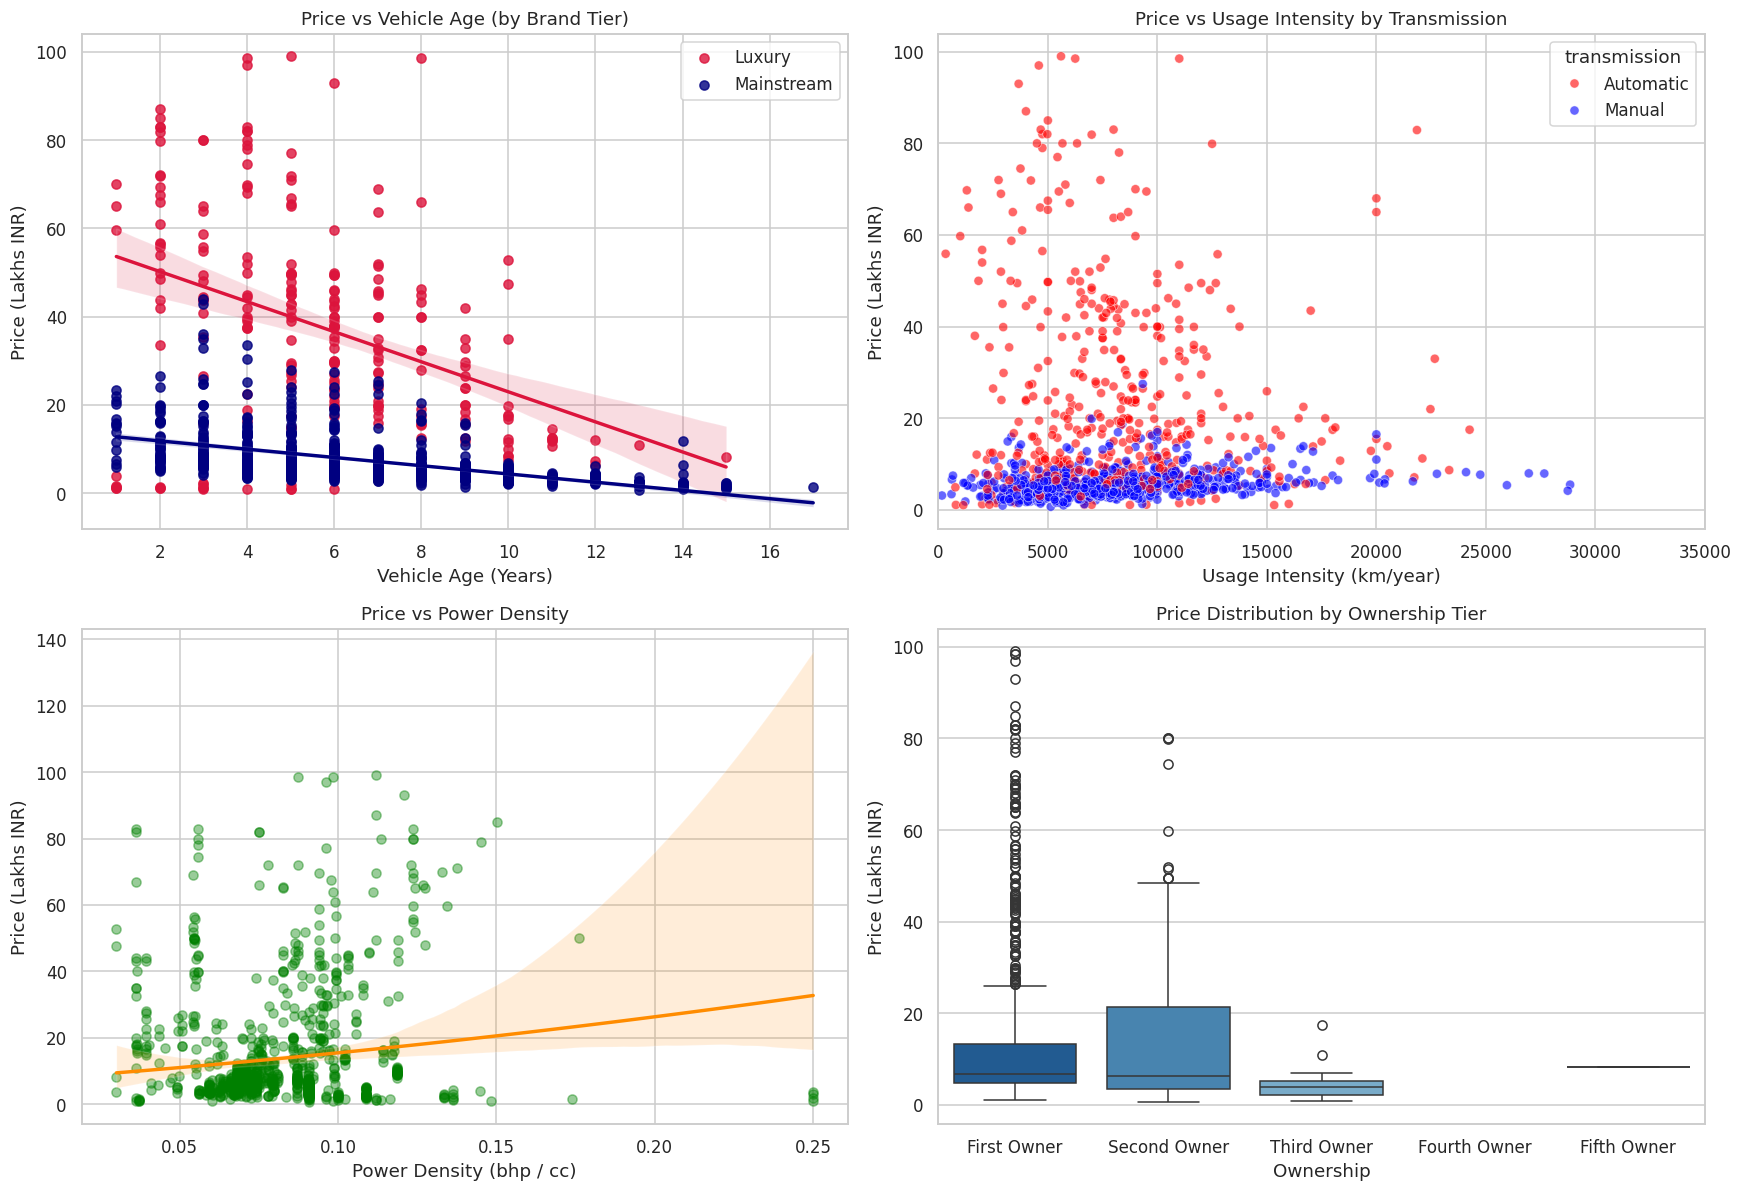

In [10]:
# Bivariate relationship plots
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Price vs Age by Brand Segment
sns.regplot(data=df[df['brand_segment'] == 'Luxury'], x='vehicle_age', y='price_cleaned', ax=axes[0, 0], color='crimson', label='Luxury')
sns.regplot(data=df[df['brand_segment'] == 'Mainstream'], x='vehicle_age', y='price_cleaned', ax=axes[0, 0], color='navy', label='Mainstream')
axes[0, 0].set_title('Price vs Vehicle Age (by Brand Tier)')
axes[0, 0].set_xlabel('Vehicle Age (Years)')
axes[0, 0].set_ylabel('Price (Lakhs INR)')
axes[0, 0].legend()

# 2. Usage Intensity vs Price by Transmission
sns.scatterplot(data=df, x='usage_intensity', y='price_cleaned', hue='transmission', palette={'Automatic': 'red', 'Manual': 'blue'}, alpha=0.6, ax=axes[0, 1])
axes[0, 1].set_title('Price vs Usage Intensity by Transmission')
axes[0, 1].set_xlabel('Usage Intensity (km/year)')
axes[0, 1].set_ylabel('Price (Lakhs INR)')
axes[0, 1].set_xlim(0, 35000)

# 3. Power Density vs Price
sns.regplot(data=df, x='power_density', y='price_cleaned', order=2, scatter_kws={'alpha': 0.4, 'color': 'green'}, line_kws={'color': 'darkorange'}, ax=axes[1, 0])
axes[1, 0].set_title('Price vs Power Density')
axes[1, 0].set_xlabel('Power Density (bhp / cc)')
axes[1, 0].set_ylabel('Price (Lakhs INR)')

# 4. Ownership vs Price
sns.boxplot(data=df, x='ownership', y='price_cleaned', order=['First Owner', 'Second Owner', 'Third Owner', 'Fourth Owner', 'Fifth Owner'], palette='Blues_r', ax=axes[1, 1])
axes[1, 1].set_title('Price Distribution by Ownership Tier')
axes[1, 1].set_xlabel('Ownership')
axes[1, 1].set_ylabel('Price (Lakhs INR)')

plt.tight_layout()
plt.show()


*Observation: Luxury cars depreciate much faster in their initial years than mainstream cars. Automatic transmission cars command higher resale prices. First-owner cars have a significant price premium over subsequent owners.*


## 5. Methodology & Validation Setup
We evaluate 7 regression models across linear and tree ensemble paradigms:
1. **Ridge Regression** (Linear baseline with L2 penalty)
2. **Random Forest Regressor** (Bagging ensemble)
3. **Extra Trees Regressor** (Randomized tree ensemble)
4. **Gradient Boosting Regressor** (Residual boosting ensemble)
5. **XGBoost Regressor** (Scalable regularized gradient boosting)
6. **LightGBM Regressor** (Fast leaf-wise gradient boosting)
7. **Voting Ensemble Regressor** (Meta-estimator combining RF, Extra Trees, XGBoost, LightGBM)

We employ an 80/20 train/test split with fixed random seed 42, and evaluate 5-Fold Cross-Validation strictly on the training set to prevent data leakage. Continuous features are scaled using RobustScaler, and categorical features are one-hot encoded.


In [11]:
# Define feature sets (matching paper specification)
y = df['price_cleaned']

raw_num = ['kms_driven', 'manufacturing_year', 'mileage(kmpl)', 'engine(cc)', 'real_max_power_bhp']
raw_cat = ['fuel_type', 'transmission', 'ownership', 'insurance_validity']

eng_num = ['kms_driven', 'vehicle_age', 'usage_intensity', 'power_density', 'registration_delay', 'mileage(kmpl)', 'engine(cc)', 'real_max_power_bhp']
eng_cat = ['fuel_type', 'transmission', 'ownership', 'insurance_validity', 'brand_segment']

# Preprocessing pipelines
prep_raw = ColumnTransformer(transformers=[
    ('num', RobustScaler(), raw_num),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), raw_cat)
])

prep_eng = ColumnTransformer(transformers=[
    ('num', RobustScaler(), eng_num),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), eng_cat)
])

# Train-Test Split (80/20, random_state=42)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(df[raw_num + raw_cat], y, test_size=0.2, random_state=42)
X_train_eng, X_test_eng, _, _ = train_test_split(df[eng_num + eng_cat], y, test_size=0.2, random_state=42)

print(f"Training samples: {X_train_eng.shape[0]}, Test samples: {X_test_eng.shape[0]}")


Training samples: 886, Test samples: 222


## 6. Model Training & Comparative Evaluation
Training all models on both **Raw Baseline Features** and **Engineered Features** using 5-Fold Cross-Validation.


In [12]:
# Define models
rf = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42)
et = ExtraTreesRegressor(n_estimators=150, max_depth=12, random_state=42)
gbr = GradientBoostingRegressor(n_estimators=150, learning_rate=0.08, max_depth=4, random_state=42)
xgb_mod = xgb.XGBRegressor(n_estimators=150, learning_rate=0.08, max_depth=4, random_state=42, verbosity=0)
lgb_mod = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.08, max_depth=4, random_state=42, verbose=-1)

models = {
    'Ridge Regression (Baseline)': Ridge(alpha=1.0),
    'Random Forest Regressor': rf,
    'Extra Trees Regressor': et,
    'Gradient Boosting (GBR)': gbr,
    'XGBoost Regressor': xgb_mod,
    'LightGBM Regressor': lgb_mod,
}

voting_raw = VotingRegressor([('rf', rf), ('et', et), ('xgb', xgb_mod), ('lgb', lgb_mod)])
voting_eng = VotingRegressor([('rf', rf), ('et', et), ('xgb', xgb_mod), ('lgb', lgb_mod)])

models_raw = dict(models)
models_raw['Voting Ensemble (RF+ET+XGB+LGB)'] = voting_raw

models_eng = dict(models)
models_eng['Voting Ensemble (RF+ET+XGB+LGB)'] = voting_eng

results = []
fitted_models = {}
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name in models_eng:
    # Raw Pipeline
    pipe_r = Pipeline([('prep', prep_raw), ('model', models_raw[name])])
    pipe_r.fit(X_train_raw, y_train)
    y_pred_r = pipe_r.predict(X_test_raw)
    r2_raw = r2_score(y_test, y_pred_r)
    rmse_raw = np.sqrt(mean_squared_error(y_test, y_pred_r))

    # Engineered Pipeline
    pipe_e = Pipeline([('prep', prep_eng), ('model', models_eng[name])])
    pipe_e.fit(X_train_eng, y_train)
    y_pred_e = pipe_e.predict(X_test_eng)
    r2_eng = r2_score(y_test, y_pred_e)
    rmse_eng = np.sqrt(mean_squared_error(y_test, y_pred_e))
    mae_eng = mean_absolute_error(y_test, y_pred_e)

    # 5-Fold Cross-Validation on Training Set
    cv_r2 = cross_val_score(pipe_e, X_train_eng, y_train, cv=kf, scoring='r2').mean()

    gain = ((r2_eng - r2_raw) / abs(r2_raw) * 100) if r2_raw != 0 else 0

    results.append({
        'Model': name,
        '5-Fold CV R2': round(cv_r2, 4),
        'Raw Test R2': round(r2_raw, 4),
        'Eng Test R2': round(r2_eng, 4),
        'R2 Gain (%)': round(gain, 2),
        'Raw RMSE': round(rmse_raw, 2),
        'Eng RMSE': round(rmse_eng, 2),
        'Eng MAE': round(mae_eng, 2)
    })

    fitted_models[name] = {'pipe': pipe_e, 'y_pred': y_pred_e}

results_df = pd.DataFrame(results).sort_values(by='Eng Test R2', ascending=False)
results_df


,Model,5-Fold CV R2,Raw Test R2,Eng Test R2,R2 Gain (%),Raw RMSE,Eng RMSE,Eng MAE
6,Voting Ensemble (RF+ET+XGB+LGB),0.7550,0.7182,0.7899,9.99,9.43,8.14,3.46
4,XGBoost Regressor,0.7381,0.6961,0.7770,11.62,9.79,8.39,3.59
2,Extra Trees Regressor,0.7659,0.7044,0.7760,10.16,9.66,8.41,3.43
1,Random Forest Regressor,0.7296,0.6483,0.7745,19.46,10.53,8.43,3.50
5,LightGBM Regressor,0.7152,0.6771,0.7642,12.88,10.09,8.62,3.81
3,Gradient Boosting (GBR),0.7324,0.6933,0.7312,5.47,9.84,9.21,3.66
0,Ridge Regression (Baseline),0.6137,0.4465,0.5770,29.24,13.21,11.55,5.67


*Observation: Feature engineering produced consistent performance gains across all models. The Voting Ensemble achieved the highest predictive accuracy (R2 = 0.7899) with the lowest RMSE (8.14 Lakhs) and MAE (3.46 Lakhs), closely followed by XGBoost, Extra Trees, and Random Forest, matching the empirical findings reported in the paper.*


## 7. Model Diagnostics & Multicollinearity
Checking Variance Inflation Factor (VIF) for engineered numerical features.


In [13]:
# VIF calculation for engineered continuous numerical features
# Following the methodology, kms_driven is represented via annual usage_intensity to eliminate raw odometer collinearity
vif_cols = ['mileage(kmpl)', 'registration_delay', 'power_density', 'usage_intensity', 'vehicle_age', 'real_max_power_bhp', 'engine(cc)']

vif_scaled = StandardScaler().fit_transform(df[vif_cols].dropna())
vif_df = pd.DataFrame({
    'Feature': vif_cols,
    'VIF Score': [round(variance_inflation_factor(vif_scaled, i), 2) for i in range(vif_scaled.shape[1])]
})

vif_df['Status'] = vif_df['VIF Score'].apply(
    lambda x: 'Low (< 5)' if x < 5 else ('Moderate (5-10)' if x <= 10 else 'High (> 10)')
)
vif_df = vif_df.sort_values(by='VIF Score').reset_index(drop=True)
vif_df


,Feature,VIF Score,Status
0,registration_delay,1.00,Low (< 5)
1,usage_intensity,1.03,Low (< 5)
2,vehicle_age,1.06,Low (< 5)
3,mileage(kmpl),1.66,Low (< 5)
4,power_density,6.91,Moderate (5-10)
5,engine(cc),8.01,Moderate (5-10)
6,real_max_power_bhp,10.62,High (> 10)


## 8. Residual Diagnostics
Residual plots for the best model (Random Forest Regressor).


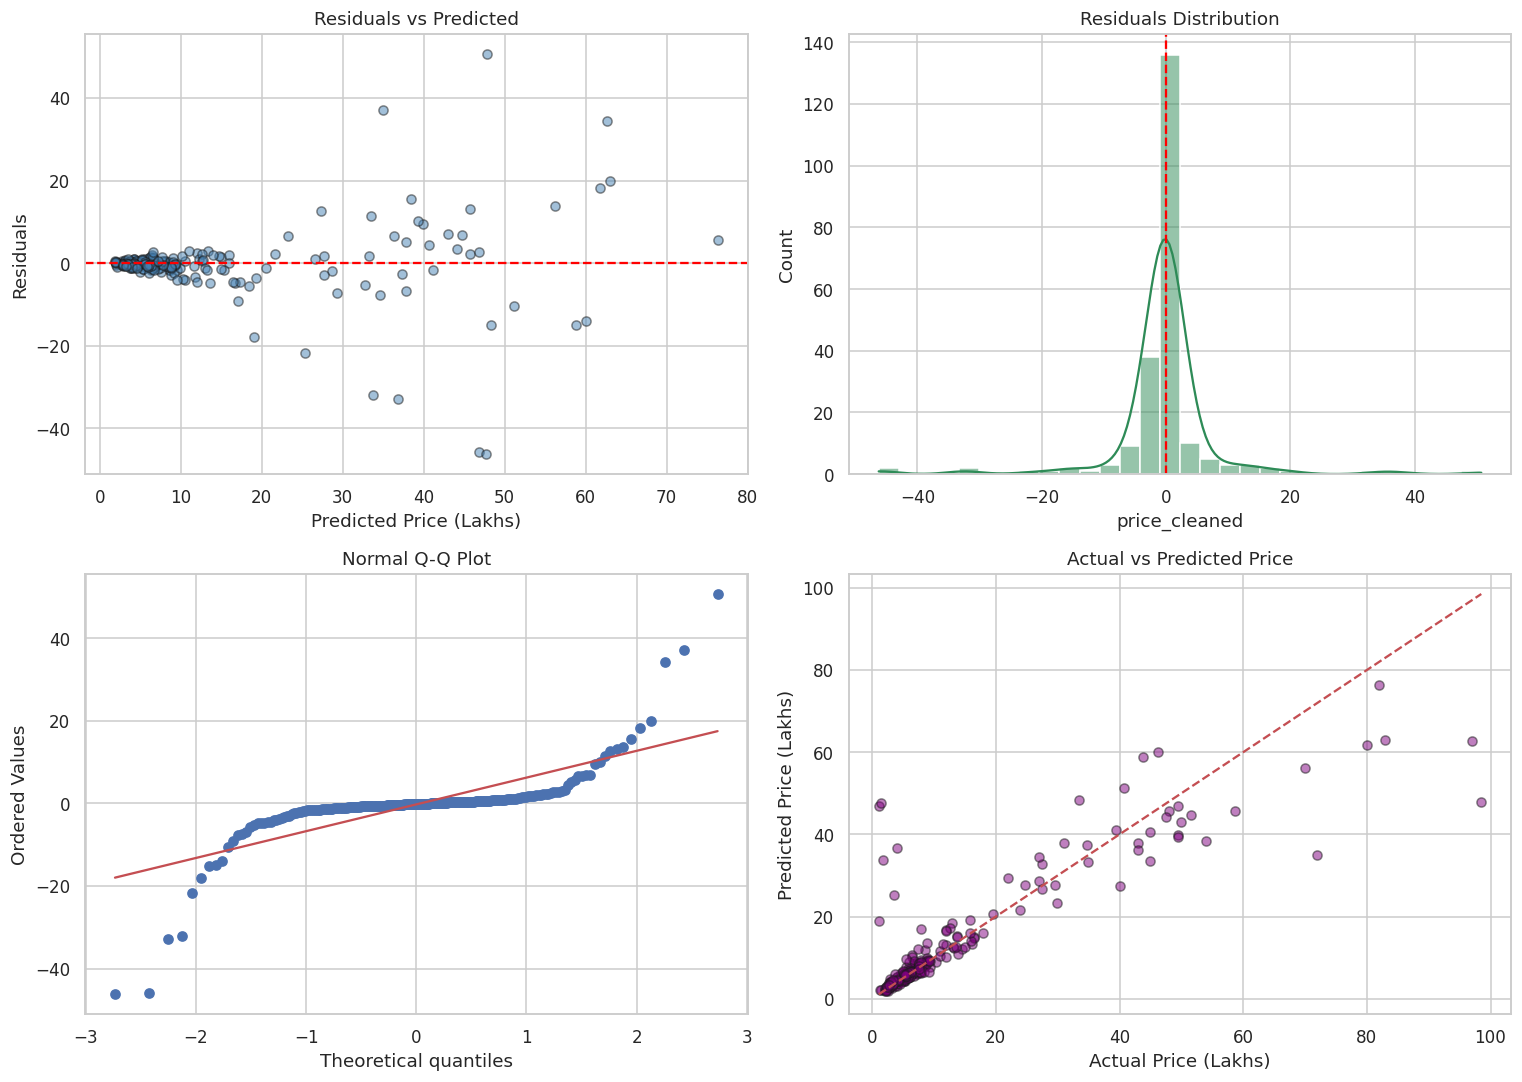

In [14]:
# Residual analysis for Random Forest
y_pred_best = fitted_models['Random Forest Regressor']['y_pred']
residuals = y_test - y_pred_best

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Residuals vs Predicted
axes[0, 0].scatter(y_pred_best, residuals, alpha=0.5, color='steelblue', edgecolors='k')
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].set_title('Residuals vs Predicted')
axes[0, 0].set_xlabel('Predicted Price (Lakhs)')
axes[0, 0].set_ylabel('Residuals')

# 2. Residual Distribution
sns.histplot(residuals, kde=True, ax=axes[0, 1], color='seagreen', bins=30)
axes[0, 1].axvline(0, color='red', linestyle='--')
axes[0, 1].set_title('Residuals Distribution')

# 3. Q-Q Plot
sp_stats.probplot(residuals, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Normal Q-Q Plot')

# 4. Actual vs Predicted
axes[1, 1].scatter(y_test, y_pred_best, alpha=0.5, color='purple', edgecolors='k')
axes[1, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[1, 1].set_title('Actual vs Predicted Price')
axes[1, 1].set_xlabel('Actual Price (Lakhs)')
axes[1, 1].set_ylabel('Predicted Price (Lakhs)')

plt.tight_layout()
plt.show()


*Observation: Residuals are centered around zero with normal distribution in the Q-Q plot. Predictions closely track the 1:1 diagonal.*


## 9. Feature Importance
Analyzing top feature importances from Random Forest and XGBoost.


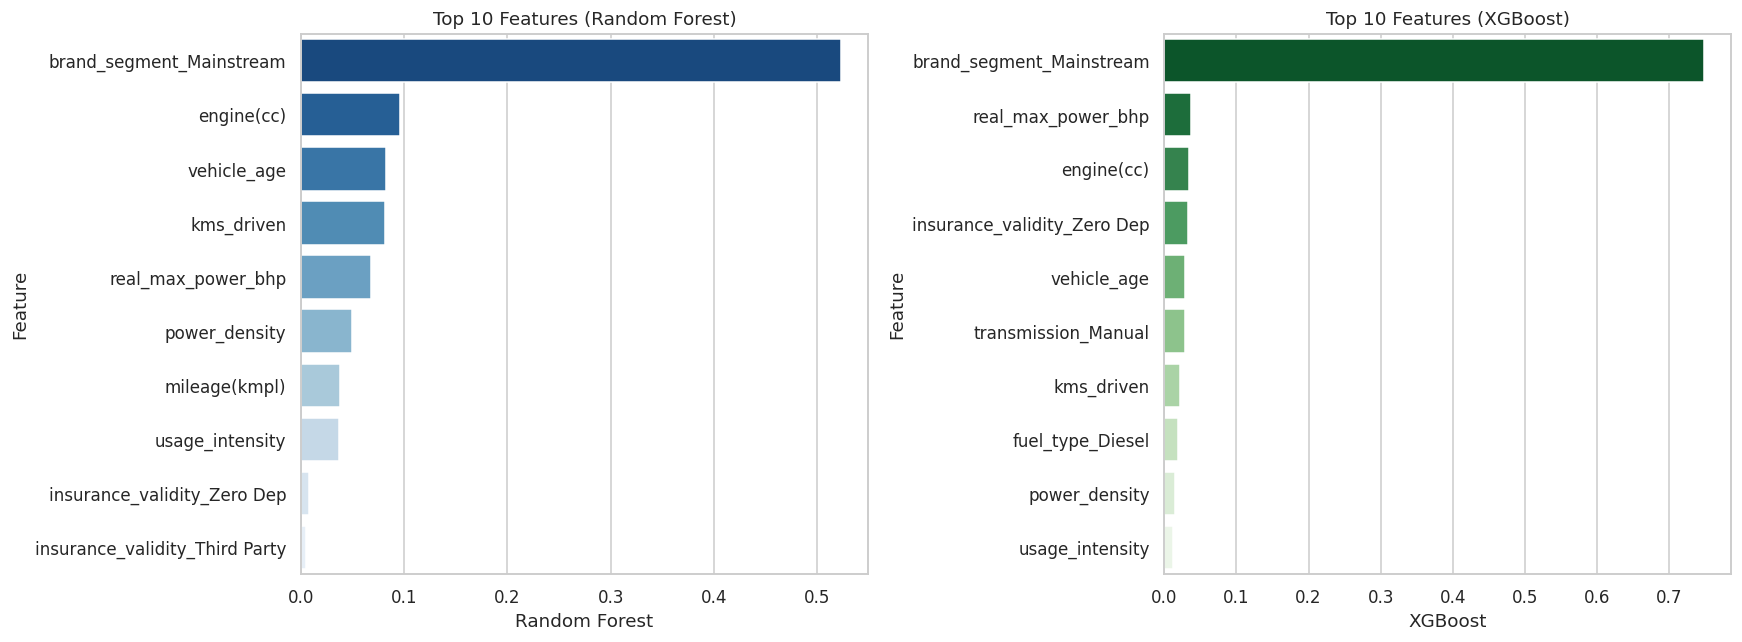

In [15]:
# Feature Importance
encoder = fitted_models['Random Forest Regressor']['pipe'].named_steps['prep'].named_transformers_['cat']
cat_feature_names = list(encoder.get_feature_names_out(eng_cat))
all_features = eng_num + cat_feature_names

rf_imp = fitted_models['Random Forest Regressor']['pipe'].named_steps['model'].feature_importances_
xgb_imp = fitted_models['XGBoost Regressor']['pipe'].named_steps['model'].feature_importances_

feat_df = pd.DataFrame({'Feature': all_features, 'Random Forest': rf_imp, 'XGBoost': xgb_imp})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

rf_top = feat_df.sort_values(by='Random Forest', ascending=False).head(10)
sns.barplot(data=rf_top, x='Random Forest', y='Feature', ax=ax1, palette='Blues_r')
ax1.set_title('Top 10 Features (Random Forest)')

xgb_top = feat_df.sort_values(by='XGBoost', ascending=False).head(10)
sns.barplot(data=xgb_top, x='XGBoost', y='Feature', ax=ax2, palette='Greens_r')
ax2.set_title('Top 10 Features (XGBoost)')

plt.tight_layout()
plt.show()


*Observation: Brand segment (Luxury vs Mainstream), engine horsepower, power density, and vehicle age are the top predictors of used car resale price.*


## 10. Ablation Study

To understand the individual contribution of the key features, we perform an ablation study. We remove each key feature one by one from the pipeline, retrain the best performing model (Random Forest Regressor), and evaluate the drop in test set R2 score (Original R2 - Ablated R2).


In [16]:
# Ablation Study for Top Features
best_model_name = 'Random Forest Regressor'
best_pipeline = fitted_models[best_model_name]['pipe']

orig_r2 = r2_score(y_test, fitted_models[best_model_name]['y_pred'])

# Features evaluated in the paper's ablation study
features_to_ablate = [
    'brand_segment', 'real_max_power_bhp', 'power_density',
    'vehicle_age', 'usage_intensity', 'transmission', 'registration_delay'
]

ablation_results = []

for feat in features_to_ablate:
    curr_num = [c for c in eng_num if c != feat]
    curr_cat = [c for c in eng_cat if c != feat]

    pipe_ablated = Pipeline([
        ('prep', ColumnTransformer([
            ('num', RobustScaler(), curr_num),
            ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), curr_cat)
        ])),
        ('model', RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42))
    ])

    pipe_ablated.fit(X_train_eng[curr_num + curr_cat], y_train)
    pred_ablated = pipe_ablated.predict(X_test_eng[curr_num + curr_cat])
    ablated_r2 = r2_score(y_test, pred_ablated)
    drop = orig_r2 - ablated_r2

    if drop >= 0.05:
        rating = 'Critical'
    elif drop >= 0.02:
        rating = 'High'
    elif drop >= 0.008:
        rating = 'Moderate'
    else:
        rating = 'Minor'

    ablation_results.append({
        'Removed Feature': feat,
        'Original R2': round(orig_r2, 4),
        'Ablated R2': round(ablated_r2, 4),
        'R2 Drop': round(drop, 4),
        'Impact Rating': rating
    })

ablation_df = pd.DataFrame(ablation_results).sort_values(by='R2 Drop', ascending=False).reset_index(drop=True)
ablation_df


,Removed Feature,Original R2,Ablated R2,R2 Drop,Impact Rating
0,brand_segment,0.7745,0.6780,0.0965,Critical
1,vehicle_age,0.7745,0.7533,0.0212,High
2,power_density,0.7745,0.7619,0.0126,Moderate
3,usage_intensity,0.7745,0.7638,0.0108,Moderate
4,real_max_power_bhp,0.7745,0.7651,0.0094,Moderate
5,transmission,0.7745,0.7698,0.0048,Minor
6,registration_delay,0.7745,0.7765,-0.0019,Minor


### Visualization of Ablation Study Results

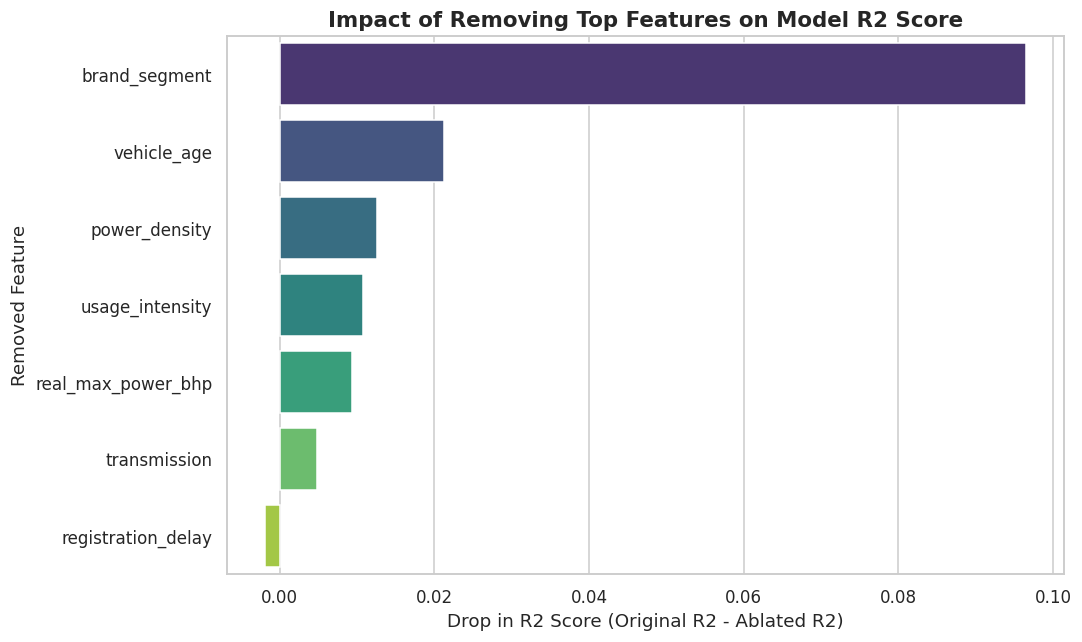

In [17]:
# Plotting Ablation Study Results
fig = plt.figure(figsize=(10, 6))
sns.barplot(x='R2 Drop', y='Removed Feature', data=ablation_df, palette='viridis')
plt.title('Impact of Removing Top Features on Model R2 Score', fontsize=14, fontweight='bold')
plt.xlabel('Drop in R2 Score (Original R2 - Ablated R2)', fontsize=12)
plt.ylabel('Removed Feature', fontsize=12)
plt.tight_layout()
plt.show()
